# Davit lift procedure – all lifting steps, seabed → barge (v2)

Produces the **davit lift summary table** (one row per lifting step): davit tensions, HOB, cable lengths, take-up lengths (TUL), pullhead tip elevation / angle / distance from stern, cable angles, stress at the davits, sag-bend stress. The last step is the weld-up position: **pipe end horizontal at barge height**.

1. **Weight switches at the waterline.** The weight per metre is the submerged value below the waterline and the in-air value above it (smooth switch over 0.1 m). In the weld-up position ~35 m of pipe is above water, so this changes the final state a lot.
2. **Horizontal equilibrium with axial tension.** The cable force is no longer purely vertical: each cable pulls along its real line (pipe attachment → davit sheave), its horizontal component acts on the pipe, and the pipe carries an axial tension **T0** at the touchdown point so that horizontal forces balance. The grounded pipe is assumed held in place by the seabed / the rest of the line (no sliding); the notebook reports T0 so you can check it against the available restraint.
3. **Large-deflection beam** (planar elastica with axial force, solved as a boundary-value problem with `scipy.integrate.solve_bvp`) instead of the small-deflection Macaulay beam. The Macaulay model is kept in sections 3–4 only to start the solver and for comparison.

Both new effects can be switched off (`air_weight`, `horizontal_forces`); with both off the solver reproduces the previous linear model to within ~2 %.

**Conventions:** HOB = elevation of the **bottom of the pipe** relative to the waterline (negative = below water), like your sheet. X is measured as in your sheet (sheaves at negative X, pipe end near the stern). Bending moment is sagging-positive. Stresses are **longitudinal (axial + bending), % SMYS** – no hoop stress / von Mises.

**Still not included:** soil interaction and sliding of the grounded pipe, dynamics/waves/currents, pipe axial strain, hydrodynamic loads.

## 1. Inputs

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import fsolve, brentq
from scipy.integrate import solve_bvp

# ================= Pipe (from document – replace with your pipe) =================
Do = 0.3239; tw = 0.0142; t_ac = 0.0005; t_coat = 0.050      # [m]
rho_steel, rho_ac, rho_coat, rho_sea = 7850., 1300., 2240., 1025.   # [kg/m3]
E = 207e9; g = 9.81
# weight per metre used in the lift: "flooded_sub" | "air_filled_sub" | "air" | "doc" (2.231 kN/m printed in the document)
weight_case = "flooded_sub"
w_override = None            # [N/m]  set a number to use your own submerged weight, e.g. 2370.0
EI_override = None           # [N.m2] set a number to use your own bending stiffness
W_pullhead = 0.0             # [N] pullhead weight in water acting at the pipe end (0 = ignore)
SMYS = 415e6; allow = 0.72   # assumed X60, 72% allowable (longitudinal) - change to suit

# ================= Model options (NEW) =================
air_weight        = True     # weight per metre switches from submerged to in-air above the waterline
w_air_override    = None     # [N/m] in-air weight per metre; None = derived from the weight case (section 2)
horizontal_forces = True     # cable horizontal components + axial tension in the pipe (grounded pipe held fixed)
T0_cap_kN         = None     # [kN] optional: horizontal tension the grounded pipe can resist (friction / restraint) - used in the checks only

# ================= Site / barge (taken from your summary sheet) =================
water_depth   = 31.3         # [m] seabed below waterline  (HOB at step 1 = -31.3)
tip_final_HOB = 2.2          # [m] FINAL elevation of the pipe end (bottom of pipe) above waterline = weld height  <-- set to your barge/weld height
datum_offset  = 3.76         # [m] cable datum: attachment Y = HOB - datum_offset  (sheet: Y1 - HOB ~ -3.76)
X_tip0        = 2.0          # [m] pullhead tip distance from stern at step 1 (sheet: 2.0)

# fixed davit sheave positions on the barge [X, Y] from the 'Cable Angle Calc' block (X2, Y2), davit 1 = nearest the pipe end
sheave_X = np.array([-4.30, -22.81, -49.32, -67.138])
sheave_Y = np.array([7.734,   6.694,   6.694,   8.154])
# For 3 davits delete one entry from sheave_X, sheave_Y, clamp_spacing and share.

# ================= Lift design =================
clamp_spacing = [20.0, 28.0, 32.0]       # [m] along the pipe: davit1-2, 2-3, 3-4 (sheet: 20 / 28 / 32)
share = [0.25, 0.25, 0.25, 0.25]         # final share of the vertical lift taken by each davit (sum = 1)
b_fixed = None                           # None: clamp position b (pipe end -> davit 1) is solved so that the end is horizontal at weld height.
                                         # number (e.g. 10.0 as in your sheet): b is fixed and only the first n-2 entries of `share_free` are chosen by you,
share_free = None                        # e.g. [0.10, 0.30] for 4 davits; the remaining shares follow from the end conditions
step_dz = 5.0                            # [m] hook height increase of davit 1 per intermediate step (sheet: ~5 m)
hob_plan = None                          # optional: your own plan, list of rows [HOB1..HOBn] (m rel. waterline) for steps 2..k;
                                         # the notebook then appends the final step(s). Example: [[-25.7,-27.3,-29.3,-30.8], ...]
T_max_kN = None                          # optional max cable tension per davit [kN] for the checks, e.g. 150.0

## 2. Section properties and weight

In [2]:
Di = Do - 2*tw; Dac = Do + 2*t_ac; Dcoat = Dac + 2*t_coat; Dhyd = Dcoat
I = np.pi/64*(Do**4 - Di**4)
A_s = np.pi/4*(Do**2 - Di**2)                      # steel area
M_dry = (np.pi/4*(Do**2-Di**2)*rho_steel + np.pi/4*(Dac**2-Do**2)*rho_ac + np.pi/4*(Dcoat**2-Dac**2)*rho_coat)
M_wat = np.pi/4*Di**2*rho_sea
Buoy_full = np.pi/4*Dhyd**2*rho_sea
Buoy_doc  = np.pi/4*(Dhyd-Di)**2*rho_sea          # expression as printed in the document (13.5 kg/m)
w_cases = {"flooded_sub": (M_dry+M_wat-Buoy_full)*g, "air_filled_sub": (M_dry-Buoy_full)*g,
           "air": M_dry*g, "doc": (M_dry-Buoy_doc)*g}
# in-air weight of the same pipe (flooded pipe keeps its water when it is lifted out of the sea)
w_air_cases = {"flooded_sub": (M_dry+M_wat)*g, "air_filled_sub": M_dry*g, "air": M_dry*g, "doc": M_dry*g}
w  = w_override  if w_override  is not None else w_cases[weight_case]          # weight per metre below the waterline [N/m]
EI = EI_override if EI_override is not None else E*I
if   w_air_override is not None: w_air = w_air_override
elif w_override     is not None: w_air = w_override + Buoy_full*g              # own submerged weight + buoyancy of the outer diameter
else:                            w_air = w_air_cases[weight_case]
w_sub = w
if not air_weight: w_air = w_sub                                              # weight switch off: submerged weight everywhere
Wp = W_pullhead
I = EI/E                                  # consistent with EI_override (used for the stress calculation)
Wz = Do/2/I                               # bending stress per unit moment [1/m3]
print(f"EI = {EI/1e6:.1f} MN.m2   pullhead = {Wp/1e3:.1f} kN")
print(f"w below waterline = {w_sub/1e3:.3f} kN/m ({'override' if w_override else weight_case})   w above waterline = {w_air/1e3:.3f} kN/m ({'on' if air_weight else 'off'})")
for k,v in w_cases.items(): print(f"   w_sub[{k:15s}] = {v/1e3:.3f} kN/m    w_air = {w_air_cases[k]/1e3:.3f} kN/m")

EI = 34.4 MN.m2   pullhead = 0.0 kN
w below waterline = 1.628 kN/m (flooded_sub)   w above waterline = 3.054 kN/m (on)
   w_sub[flooded_sub    ] = 1.628 kN/m    w_air = 3.054 kN/m
   w_sub[air_filled_sub ] = 0.939 kN/m    w_air = 2.364 kN/m
   w_sub[air            ] = 2.364 kN/m    w_air = 2.364 kN/m
   w_sub[doc            ] = 2.232 kN/m    w_air = 2.364 kN/m


## 3. Linear beam model of the previous notebook (kept as a first estimate and for comparison)
Small-deflection Macaulay beam, vertical cable forces only, one weight per metre. It is used here to **start** the full solver and to show how much the two new effects change the result.

In [3]:
def fields(x, L, dist, R, F, w, EI):
    # beam response, x from touchdown point A; davits at x = L - dist; returns shear, moment (sagging +), slope, height
    x = np.asarray(x, float); xi = L - np.asarray(dist, float)
    V = R - w*x; M = R*x - w*x**2/2; th = R*x**2/2 - w*x**3/6; y = R*x**3/6 - w*x**4/24
    for Fk, xk in zip(F, xi):
        m = np.maximum(x - xk, 0.0)
        V = V + Fk*(x >= xk); M = M + Fk*m; th = th + Fk*m**2/2; y = y + Fk*m**3/6
    return V, M, th/EI, y/EI

def final_state(w, EI, d_end, offsets, share):
    # pipe end at height d_end, horizontal, free end; unknowns L, b (end->davit 1), total force F, touchdown reaction R
    offsets = np.asarray(offsets, float); share = np.asarray(share, float)
    def resid(z):
        L, b, F, R = z; dist = b + offsets; Fi = F*share
        return [(R+F-w*L)/(w*L),
                (R*L + np.sum(Fi*dist) - w*L**2/2)/(w*L**2),
                (R*L**2/2 + np.sum(Fi*dist**2)/2 - w*L**3/6)/(w*L**3),
                ((R*L**3/6 + np.sum(Fi*dist**3)/6 - w*L**4/24)/EI - d_end)/d_end]
    L0 = (216*d_end*EI/w)**0.25
    z, info, ier, msg = fsolve(resid, [L0, L0/3 - np.sum(share*offsets), 0.75*w*L0, 0.25*w*L0], full_output=True, xtol=1e-12)
    if ier != 1: raise RuntimeError("final-state solver did not converge: " + msg)
    return z

def solve_disp(h, dist, w, EI, W_tip=0.0):
    # davit hook heights h prescribed -> touchdown length L, touchdown reaction R, vertical davit forces F
    h = np.asarray(h, float); dist = np.asarray(dist, float); n = len(h)
    def lin(L):
        x = L - dist
        A = np.zeros((n+1, n+1)); rhs = np.zeros(n+1)
        for i in range(n):
            A[i, 0] = x[i]**3/6/EI
            for j in range(n): A[i, 1+j] = max(x[i]-x[j], 0.0)**3/6/EI
            rhs[i] = h[i] + w*x[i]**4/24/EI
        A[n, :] = 1; rhs[n] = w*L + W_tip
        s = np.linalg.solve(A, rhs); R, F = s[0], s[1:]
        return R*L + np.sum(F*dist) - w*L**2/2 + 0*W_tip, R, F       # moment about the pipe end
    Ls_ = np.linspace(dist.max()*1.0005, dist.max() + 400, 3000)
    rs = np.array([lin(L)[0] for L in Ls_])
    k = np.where(np.sign(rs[:-1])*np.sign(rs[1:]) < 0)[0]
    if len(k) == 0: raise RuntimeError("no touchdown length found for these hook heights")
    L = brentq(lambda L: lin(L)[0], Ls_[k[0]], Ls_[k[0]+1], xtol=1e-10)
    return (L,) + lin(L)[1:]

## 4. Linear first estimate of the final state (pipe end horizontal at weld height)

In [4]:
offsets = np.concatenate([[0.0], np.cumsum(clamp_spacing)])
n = len(offsets); share = np.asarray(share, float)
assert len(sheave_X) == n == len(share), "check number of davits / share"
d_end = water_depth + tip_final_HOB                       # pipe-end height above the seabed in the final state

def final_state_fixed_b(w, EI, d_end, dist, free):
    # clamp positions fixed; first n-2 shares given, share n-1 follows from the end conditions, share n = remainder
    free = np.asarray(free, float)
    def sh(s_):
        out = np.zeros(n); out[:n-2] = free; out[n-2] = s_; out[n-1] = 1 - free.sum() - s_; return out
    def resid(z):
        L, F, R, s_ = z; Fi = F*sh(s_)
        return [(R+F-w*L)/(w*L), (R*L + np.sum(Fi*dist) - w*L**2/2)/(w*L**2),
                (R*L**2/2 + np.sum(Fi*dist**2)/2 - w*L**3/6)/(w*L**3),
                ((R*L**3/6 + np.sum(Fi*dist**3)/6 - w*L**4/24)/EI - d_end)/d_end]
    L0 = (216*d_end*EI/w)**0.25
    z, info, ier, msg = fsolve(resid, [L0, 0.75*w*L0, 0.25*w*L0, 0.25], full_output=True, xtol=1e-12)
    if ier != 1: raise RuntimeError("final-state solver did not converge: " + msg)
    return z[0], z[1], z[2], sh(z[3])

if b_fixed is None:
    assert abs(share.sum()-1) < 1e-9, "share must sum to 1"
    L_f, b, F_f, R_f = final_state(w_sub, EI, d_end, offsets, share)
    dist = b + offsets
else:
    assert share_free is not None and len(share_free) == n-2, f"give {n-2} values in share_free"
    b = b_fixed; dist = b + offsets
    L_f, F_f, R_f, share = final_state_fixed_b(w_sub, EI, d_end, dist, share_free)
Fi_f = F_f*share
_, _, _, h_final = fields(L_f - dist, L_f, dist, R_f, Fi_f, w_sub, EI)   # hook heights above seabed
lin_final = dict(L=L_f, b=b, F=F_f, R=R_f, share=share.copy(), h=h_final.copy())
print("LINEAR first estimate (submerged weight everywhere, vertical cable forces only):")
print(f"  lifted length L = {L_f:.1f} m,  clamp 1 is {b:.2f} m from the pipe end,  total lift {F_f/1e3:.1f} kN,  touchdown reaction {R_f/1e3:.1f} kN")
print("  final HOB at davits [m rel. waterline]:", np.round(h_final - water_depth, 2))
assert L_f > dist.max(), "all davits must be on the lifted part (L > last clamp distance) - reduce spacing"

LINEAR first estimate (submerged weight everywhere, vertical cable forces only):
  lifted length L = 142.8 m,  clamp 1 is 21.34 m from the pipe end,  total lift 196.6 kN,  touchdown reaction 36.0 kN
  final HOB at davits [m rel. waterline]: [  1.79  -1.66 -11.85 -24.7 ]


## 5. Full model – large-deflection beam with waterline weight and horizontal equilibrium

The pipe is a planar elastica of arc length `s` measured from the touchdown point. Along the pipe

`θ' = M/EI`, `M' = Py·cosθ − Px·sinθ`, `x' = cosθ`, `y' = sinθ`, `Px' = 0`, `Py' = −w(y)`

where `(Px, Py)` is the resultant of all external forces on the part between the touchdown point and `s` (touchdown reaction `R` and tension `T0`, weight, cable forces) and `w(y)` is the submerged weight below the waterline and the in-air weight above it. At each clamp the cable force `T_i` (acting along the line from the pipe attachment to the sheave) adds `T_i·(dx, dy)/|cable|` to `(Px, Py)`; the attachment position follows from the solved pipe shape, so cable angles and forces are consistent with the deformed pipe. The grounded pipe is held in place, so the touchdown point is at `X_tip0 − L`.

Unknowns per step: lifted length `L`, reaction `R`, tension `T0`, cable tensions `T_i`; conditions: touchdown (`y = θ = M = 0`), hook heights prescribed, free end (`M = 0`, `Px = 0`, `Py = pullhead weight`). In the final state the end slope and elevation are prescribed instead and `b` (or one share) becomes unknown. The pipe is split at the clamps (multiple shooting) so that the boundary layer near the touchdown point, which becomes stiff when `T0` is large, is solved reliably.

In [5]:
Ls, Fs = 100.0, 1.0e5                     # length / force scales used to non-dimensionalise the BVP
kappa = Fs*Ls**2/EI
DELTA_W = 0.10                            # [m] smoothing length of the weight switch at the waterline
offs = np.asarray(offsets, float); spacing = np.asarray(clamp_spacing, float)
f_air = 1.0 if air_weight else 0.0
f_hor = 1.0 if horizontal_forces else 0.0

def w_of_y(y, fa):
    # weight per metre at height y above the seabed (fa = 0: submerged everywhere, 1: switch at the waterline)
    return w_sub + fa*(w_air - w_sub)*0.5*(1 + np.tanh((y - water_depth)/DELTA_W))

class Prob:
    """BVP of one lift state. mode 'step': hook heights h given, clamp distance b given.
       mode 'final': end elevation d_end and end slope 0 given, shares given; b is free (share_free None) or fixed (b given, share n-1 free)."""
    def __init__(s, mode, fa, fh, h=None, b=None, d_end=None, shares=None, share_free=None, W_tip=0.0):
        s.mode, s.fa, s.fh, s.h, s.b, s.d_end, s.W_tip = mode, fa, fh, h, b, d_end, W_tip
        s.shares, s.share_free = shares, share_free
        s.free_b = (mode == 'final' and share_free is None)
        s.npar = n + 3 + (1 if mode == 'final' else 0)
    def unpack(s, p):
        L, R, T0, T = p[0], p[1], p[2], p[3:3+n]
        ex = p[3+n] if s.mode == 'final' else None
        b_ = ex if s.free_b else s.b/Ls
        return L, R, T0, T, b_, ex
    def ells(s, L, b_):                    # segment lengths /Ls, ordered from the touchdown point: TD->davit n, ..., davit 2->davit 1, davit 1->tip
        e = [L - b_ - offs[-1]/Ls]
        for k in range(1, n): e.append(spacing[n-1-k]/Ls)
        e.append(b_)
        return e
    def fun(s, xi, Y, p):
        L, R, T0, T, b_, ex = s.unpack(p); ell = s.ells(L, b_)
        dY = np.empty_like(Y)
        for k in range(n+1):
            th, m_, x_, y_, px, py = Y[6*k:6*k+6]; l = ell[k]
            dY[6*k]   = l*kappa*m_
            dY[6*k+1] = l*(py*np.cos(th) - px*np.sin(th))
            dY[6*k+2] = l*np.cos(th)
            dY[6*k+3] = l*np.sin(th)
            dY[6*k+4] = 0.0
            dY[6*k+5] = -l*w_of_y(y_*Ls, s.fa)*Ls/Fs
        return dY
    def bc(s, ya, yb, p):
        L, R, T0, T, b_, ex = s.unpack(p)
        res = [ya[0], ya[1], ya[2], ya[3], ya[4] + T0, ya[5] - R]
        Fv = np.zeros(n)
        for c in range(n):                 # clamp at the end of segment c = davit n-1-c (0-based)
            i = n-1-c
            e = yb[6*c:6*c+6]; st = ya[6*(c+1):6*(c+2)]
            Xj = X_tip0 - L*Ls + e[2]*Ls; Yj = e[3]*Ls - water_depth - datum_offset
            dx = sheave_X[i]-Xj; dy = sheave_Y[i]-Yj; ln = np.hypot(dx, dy)
            Hx = s.fh*T[i]*dx/ln; Fv[i] = T[i]*dy/ln
            res += [st[0]-e[0], st[1]-e[1], st[2]-e[2], st[3]-e[3], st[4]-e[4]-Hx, st[5]-e[5]-Fv[i]]
            if s.mode == 'step': res.append(e[3] - s.h[i]/Ls)
        e = yb[6*n:6*n+6]
        res += [e[1], e[4], e[5] - s.W_tip/Fs]                       # free end: M = 0, Px = 0, Py = pullhead weight
        if s.mode == 'final':
            sh = np.asarray(s.shares, float) if s.free_b else np.concatenate([s.share_free, [ex], [0.0]])
            tot = Fv.sum()
            for i in range(n-1): res.append(Fv[i] - sh[i]*tot)       # share of the vertical lift per davit
            res += [e[0], e[3] - s.d_end/Ls]                          # end horizontal, at weld height
        return np.array(res)

xi0 = np.linspace(0, 1, 41)
def run_from(P, sol0):
    return solve_bvp(P.fun, P.bc, xi0, sol0.sol(xi0), np.asarray(sol0.p)[:P.npar], tol=1e-6, bc_tol=1e-6, max_nodes=100000)

def homotopy(make_P, q0, q1, sol0, depth=0):
    # move from solved state q0 (solution sol0) to q1; the path is bisected automatically when the solver fails
    P = make_P(q1); s = run_from(P, sol0)
    if s.status == 0: return s, P
    if depth >= 6: raise RuntimeError(f"BVP solver did not converge ({s.message}) - try a smaller step or different inputs")
    qm = 0.5*(np.asarray(q0, float) + np.asarray(q1, float))
    sm, Pm = homotopy(make_P, q0, qm, sol0, depth+1)
    return homotopy(make_P, qm, q1, sm, depth+1)

def lin_guess(P, L, bb, R, Fv, share_n2):
    # starting values from the linear beam: mesh, states (scaled) and parameters
    dist_ = bb + offs
    ell = P.ells(L/Ls, bb/Ls); starts = np.concatenate([[0], np.cumsum(ell)])*Ls
    Y = np.zeros((6*(n+1), len(xi0)))
    for k in range(n+1):
        sk = starts[k] + xi0*ell[k]*Ls
        V, M, th, y = fields(sk, L, dist_, R, Fv, w_sub, EI)
        Y[6*k+0] = th; Y[6*k+1] = M/(Fs*Ls); Y[6*k+2] = sk/Ls; Y[6*k+3] = y/Ls; Y[6*k+5] = V/Fs
    _, _, _, yc = fields(L - dist_, L, dist_, R, Fv, w_sub, EI)
    Tg = np.zeros(n)
    for i in range(n):
        dx = sheave_X[i] - (X_tip0 - L + (L - dist_[i])); dy = sheave_Y[i] - (yc[i] - water_depth - datum_offset)
        Tg[i] = Fv[i]*np.hypot(dx, dy)/dy
    p = np.concatenate([[L/Ls, R/Fs, 0.0], Tg/Fs, [bb/Ls if P.free_b else share_n2]])
    class G: pass
    g_ = G(); g_.p = p; g_.sol = lambda xi, Y=Y: Y
    return g_

## 6. Final state with the full model – pipe end horizontal at weld height

In [6]:
def make_final(q):
    if b_fixed is None: return Prob('final', q[0], q[1], d_end=d_end, shares=share)
    return Prob('final', q[0], q[1], d_end=d_end, b=b_fixed, share_free=np.asarray(share_free, float))

P0 = make_final((0.0, 0.0))
g0 = lin_guess(P0, L_f, b, R_f, Fi_f, share[n-2])
s0 = run_from(P0, g0)
if s0.status != 0: raise RuntimeError("starting solution (linear-equivalent model) did not converge: " + s0.message)
sol_fin, P_fin = homotopy(make_final, (0, 0), (f_air, 0), s0)               # 1) weight switch at the waterline
sol_fin, P_fin = homotopy(make_final, (f_air, 0), (f_air, f_hor), sol_fin)   # 2) horizontal cable forces + axial tension

L_fin, R_fin, T0_fin, T_fin, b_fin, ex_fin = P_fin.unpack(sol_fin.p)
L_fin, R_fin, T0_fin, T_fin, b = L_fin*Ls, R_fin*Fs, T0_fin*Fs, T_fin*Fs, b_fin*Ls
dist = b + offsets
h_final = np.array([sol_fin.sol(np.array([1.0]))[6*(n-1-i)+3, 0]*Ls for i in range(n)])      # hook heights above seabed
Fv_fin = np.array([T_fin[i]*(sheave_Y[i] - (h_final[i]-water_depth-datum_offset))/np.hypot(
        sheave_X[i] - (X_tip0 - L_fin + sol_fin.sol(np.array([1.0]))[6*(n-1-i)+2, 0]*Ls),
        sheave_Y[i] - (h_final[i]-water_depth-datum_offset)) for i in range(n)])
share = Fv_fin/Fv_fin.sum()
print("FULL MODEL final state:   (linear first estimate in brackets)")
print(f"  lifted length L = {L_fin:.1f} m ({lin_final['L']:.1f}),  clamp 1 is {b:.2f} m from the pipe end ({lin_final['b']:.2f})")
print(f"  total vertical lift {Fv_fin.sum()/1e3:.1f} kN ({lin_final['F']/1e3:.1f}),  touchdown reaction {R_fin/1e3:.1f} kN ({lin_final['R']/1e3:.1f}),  touchdown tension T0 = {T0_fin/1e3:.1f} kN")
print("  final HOB at davits [m rel. waterline]:", np.round(h_final - water_depth, 2), " (", np.round(lin_final['h'] - water_depth, 2), ")")
print("  final share of the vertical lift per davit [%]:", np.round(100*share, 1))
if b_fixed is not None: print("  (negative share = davit would have to push - change share_free)")

FULL MODEL final state:   (linear first estimate in brackets)
  lifted length L = 198.1 m (142.8),  clamp 1 is 14.64 m from the pipe end (21.34)
  total vertical lift 356.7 kN (196.6),  touchdown reaction 15.0 kN (36.0),  touchdown tension T0 = 402.9 kN
  final HOB at davits [m rel. waterline]: [  2.03  -0.02  -5.74 -14.45]  ( [  1.79  -1.66 -11.85 -24.7 ] )
  final share of the vertical lift per davit [%]: [25. 25. 25. 25.]


## 7. Step-by-step solution

In [7]:
sheave_X = np.asarray(sheave_X, float); sheave_Y = np.asarray(sheave_Y, float)
b_phys = b

# ---- plan: list of (label, hook heights above seabed, pullhead weight, flat?) ----
if hob_plan is None:
    k_max = int(np.ceil(h_final[0]/step_dz - 1e-9))
    alphas = np.arange(1, k_max)*step_dz/h_final[0]
    plan_h = [a*h_final for a in alphas]
else:
    plan_h = [np.asarray(r, float) + water_depth for r in hob_plan]

steps = [("Initial", np.zeros(n), Wp, True)]
steps += [("", hk, Wp, False) for hk in plan_h]
if Wp > 0: steps += [("Final", h_final, Wp, False)]
steps += [("Final without pullhead" if Wp > 0 else "Final", h_final, 0.0, False)]

make_step = lambda q: Prob('step', f_air, f_hor, h=q[1:], b=b_phys, W_tip=q[0])

# solve backwards from the final state (known solution) towards the seabed; every state starts from its neighbour
solved = {}
k_last = len(steps) - 1
q_prev = np.concatenate([[0.0], h_final])
Pst = make_step(q_prev); sol_prev = run_from(Pst, sol_fin)
if sol_prev.status != 0: raise RuntimeError("final state could not be re-solved in step form: " + sol_prev.message)
solved[k_last] = (sol_prev, Pst)
for k in range(k_last-1, 0, -1):
    q_new = np.concatenate([[steps[k][2]], steps[k][1]])
    sol_prev, Pst = homotopy(make_step, q_prev, q_new, sol_prev)
    q_prev = q_new; solved[k] = (sol_prev, Pst)

def analyse(sol, P, W_tip):
    # every quantity of the summary table for one solved state
    L_, R_, T0_, T_, b_, _ = P.unpack(sol.p); L_*=Ls; R_*=Fs; T0_*=Fs; T_ = T_*Fs
    ell = P.ells(L_/Ls, b_); X_td = X_tip0 - L_
    cols = []
    for k in range(n+1):
        xi = np.linspace(0, 1, max(int(ell[k]*Ls*4), 20)); Z = sol.sol(xi)[6*k:6*k+6]
        cols.append(Z)
    Z = np.hstack(cols)
    th, M, x, y, px, py = Z[0], Z[1]*Fs*Ls, Z[2]*Ls, Z[3]*Ls, Z[4]*Fs, Z[5]*Fs
    Nax = -(px*np.cos(th) + py*np.sin(th))                   # axial tension in the pipe [N]
    comb = (Nax/A_s + np.abs(M)*Wz)/SMYS*100                 # longitudinal stress, extreme fibre [% SMYS]
    Xj = np.zeros(n); hob = np.zeros(n); sig_dav = np.zeros(n); F = np.zeros(n)
    for c in range(n):
        i = n-1-c; e = sol.sol(np.array([1.0]))[6*c:6*c+6, 0]
        Xj[i] = X_td + e[2]*Ls; hob[i] = e[3]*Ls - water_depth
        sig_dav[i] = (-(e[4]*Fs*np.cos(e[0]) + e[5]*Fs*np.sin(e[0]))/A_s + abs(e[1]*Fs*Ls)*Wz)/SMYS*100
    Yj = hob - datum_offset; dx = sheave_X - Xj; dy = sheave_Y - Yj; cab = np.hypot(dx, dy)
    F = T_*dy/cab; Hx = T_*dx/cab
    et = sol.sol(np.array([1.0]))[6*n:6*n+6, 0]
    sag = comb[M > 0].max() if (M > 0).any() else 0.0
    above = np.sum((y[1:] > water_depth)*np.diff(np.concatenate([[0], np.cumsum(np.hypot(np.diff(x), np.diff(y)))])) ) if False else None
    s_arc = np.concatenate([[0], np.cumsum(np.hypot(np.diff(x), np.diff(y)))])
    above = np.sum(np.diff(s_arc)*(0.5*(y[1:]+y[:-1]) > water_depth))
    return dict(F=F, H=Hx, T=T_, L=L_, R=R_, T0=T0_, hob=hob, cable=cab, ang=np.degrees(np.arctan2(dx, dy)),
                tip_el=-water_depth + et[3]*Ls, tip_ang=np.degrees(et[0]), X_tip=X_td + et[2]*Ls, Xj=Xj, Yj=Yj,
                sig_dav=sig_dav, sig_sag=sag, sig_max=comb.max(), above=above, curve=(X_td + x, y - water_depth),
                ok=bool((y.min() > -0.02) and (R_ > -1e3) and (T_.min() > 0)))

def analyse_flat():
    # initial state: pipe lying on the seabed, davit attachments on the flat pipe
    hob = np.full(n, -water_depth); Xj = X_tip0 - dist; Yj = hob - datum_offset
    dx = sheave_X - Xj; dy = sheave_Y - Yj; cab = np.hypot(dx, dy)
    return dict(F=np.full(n, np.nan), H=np.full(n, np.nan), T=np.full(n, np.nan), L=np.nan, R=np.nan, T0=np.nan, hob=hob, cable=cab,
                ang=np.degrees(np.arctan2(dx, dy)), tip_el=-water_depth, tip_ang=0.0, X_tip=X_tip0, Xj=Xj, Yj=Yj,
                sig_dav=np.full(n, np.nan), sig_sag=np.nan, sig_max=np.nan, above=0.0,
                curve=(np.array([X_tip0 - dist.max()*1.4, X_tip0]), np.array([-water_depth, -water_depth])), ok=True)

res = [analyse_flat()] + [analyse(*solved[k][:1], solved[k][1], steps[k][2]) for k in range(1, len(steps))]
for r in res: r["TUL"] = res[0]["cable"] - r["cable"]
print(f"{len(res)} steps computed.  Pipe pull-in at the final step: {X_tip0 - res[-1]['X_tip']:.2f} m")

8 steps computed.  Pipe pull-in at the final step: 3.86 m


## 8. Lift summary table (same layout as the sheet)

In [8]:
lab = [f"{i+1} {s[0]}".strip() for i, s in enumerate(steps)]
def block(name, key):
    arr = np.array([r[key] for r in res]); arr = arr if arr.ndim == 2 else arr[:, None]
    return {(name, f"#{j+1}" if arr.shape[1] > 1 else ""): arr[:, j] for j in range(arr.shape[1])}
cols = {}
Tcab = np.array([r["T"]/1e3 for r in res])                 # cable tensions [kN]
cols.update({("Davit tension (kN)", f"#{j+1}"): Tcab[:, j] for j in range(n)})
cols.update(block("HOB bottom of pipe (m)", "hob"))
cols.update(block("Davit cable length (m)", "cable"))
cols.update(block("Take-up length TUL (m)", "TUL"))
cols[("Pullhead tip elevation (m)", "")]  = [r["tip_el"] for r in res]
cols[("Pullhead tip angle (deg)", "")]    = [r["tip_ang"] for r in res]
cols[("Pullhead tip dist. from stern (m)", "")] = [r["X_tip"] for r in res]
cols.update(block("Cable angle from vertical (deg)", "ang"))
cols.update({("Stress at davits (%SMYS, axial+bending)", f"#{j+1}"): [r["sig_dav"][j] for r in res] for j in range(n)})
cols[("Sagbend stress (%SMYS, axial+bending)", "")] = [r["sig_sag"] for r in res]
cols[("Touchdown tension T0 (kN)", "")] = [r["T0"]/1e3 for r in res]
cols[("Lifted length L (m)", "")] = [r["L"] for r in res]
cols[("Pipe above waterline (m)", "")] = [r["above"] for r in res]
table = pd.DataFrame(cols, index=lab); table.index.name = "Step"
table.columns = pd.MultiIndex.from_tuples(table.columns)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 60)
display(table.round(2))

Davit tension (kN)                         HOB bottom of pipe (m)                      Davit cable length (m)                      Take-up length TUL (m)                      Pullhead tip elevation (m) Pullhead tip angle (deg)  \
                          #1      #2      #3      #4                     #1     #2     #3     #4                     #1     #2     #3     #4                     #1     #2     #3     #4                                                       
Step                                                                                                                                                                                                                                           
1 Initial                NaN     NaN     NaN     NaN                 -31.30 -31.30 -31.30 -31.30                  43.60  42.90  43.26  50.18                   0.00   0.00   0.00   0.00                     -31.30                     0.00   
2                      45.61   35.75   47.70   87.65                 -26.30 -26.61 -27.47 -28.77                  38.74  38.38  39.61  48.08                   4.86   4.51   3.65   2.10                     -26.74                    -2.06   
3                      44.51   40.25   45.62  105.05                 -21.30 -21.92 -23.63 -26.25                  33.97  33.98  36.07  46.09                   9.63   8.91   7.20   4.08                     -21.56                    -1.37   
4                      43.97   45.17   46.07  120.24                 -16.30 -17.22 -19.80 -23.72                  29.35  29.74  32.64  44.23                  14.25  13.15  10.62   5.95                     -16.38                    -0.66   
5                      44.36   51.59   49.46  134.96                 -11.30 -12.53 -15.96 -21.19                  24.95  25.74  29.38  42.47                  18.65  17.16  13.88   7.71                     -11.19                     0.06   
6                      46.70   61.88   57.69  148.89                  -6.30  -7.84 -12.13 -18.66                  20.89  22.09  26.33  40.82                  22.71  20.81  16.93   9.36                      -6.01                     0.79   
7                      54.01   83.41   76.49  157.67                  -1.30  -3.15  -8.29 -16.14                  17.41  18.96  23.53  39.23                  26.19  23.93  19.73  10.95                      -0.82                     1.54   
8 Final               145.47  145.95  119.58  128.70                   2.03  -0.02  -5.74 -14.45                  15.44  17.15  21.72  38.06                  28.16  25.75  21.54  12.12                       2.20                     0.00   

          Pullhead tip dist. from stern (m) Cable angle from vertical (deg)                      Stress at davits (%SMYS, axial+bending)                      Sagbend stress (%SMYS, axial+bending) Touchdown tension T0 (kN) Lifted length L (m)  \
                                                                         #1     #2     #3     #4                                      #1     #2     #3     #4                                                                                       
Step                                                                                                                                                                                                                                                
1 Initial                              2.00                           11.03  13.25  15.17  30.55                                     NaN    NaN    NaN    NaN                                   NaN                       NaN                 NaN   
2                                      1.84                           12.67  15.07  16.81  32.19                                   41.20  21.55  26.95  63.34                                 40.70                     79.79              135.57   
3                                      1.47                           15.13  17.73  19.07  34.12                                   41.24  29.79 

## 9. Checks for the procedure

In [9]:
allow_pct = allow*100
for lbl, r in zip(lab, res):
    msg = []
    if lbl != lab[0]:
        if r["T"].min() <= 0: msg.append("slack cable (tension <= 0) at davit " + str(int(np.argmin(r["T"]))+1))
        if r["R"] < -1e3: msg.append("negative touchdown reaction")
        if T_max_kN is not None and r["T"].max()/1e3 > T_max_kN: msg.append(f"tension {r['T'].max()/1e3:.0f} kN > {T_max_kN} kN at davit {int(np.argmax(r['T']))+1}")
        if T0_cap_kN is not None and r["T0"]/1e3 > T0_cap_kN: msg.append(f"touchdown tension T0 {r['T0']/1e3:.0f} kN > restraint {T0_cap_kN} kN: grounded pipe would slide - results not valid")
        if r["sig_max"] > allow_pct: msg.append(f"stress {r['sig_max']:.0f}% SMYS > {allow_pct:.0f}%")
        if not r["ok"]: msg.append("pipe below seabed or negative load")
    print(f"{lbl:28s}", "OK" if not msg else "** " + "; ".join(msg))
tf = res[-1]
print()
print(f"Final end condition: tip elevation {tf['tip_el']:.3f} m (target {tip_final_HOB} m), tip angle {tf['tip_ang']:.3f} deg (target 0)")
print("Final share of vertical lift [%]:", np.round(100*tf['F']/tf['F'].sum(), 1))
print(f"Final step: sum of cable horizontal components {tf['H'].sum()/1e3:.0f} kN (= touchdown tension T0 {tf['T0']/1e3:.0f} kN), sum of vertical components {tf['F'].sum()/1e3:.0f} kN")

1 Initial                    OK
2                            OK
3                            ** stress 78% SMYS > 72%
4                            ** stress 85% SMYS > 72%
5                            ** stress 87% SMYS > 72%
6                            ** stress 82% SMYS > 72%
7                            OK
8 Final                      ** stress 79% SMYS > 72%

Final end condition: tip elevation 2.200 m (target 2.2 m), tip angle 0.000 deg (target 0)
Final share of vertical lift [%]: [25. 25. 25. 25.]
Final step: sum of cable horizontal components 403 kN (= touchdown tension T0 403 kN), sum of vertical components 357 kN


## 10. Validation – global equilibrium of every solved state and comparison with the linear model

In [10]:
def equilibrium(sol, P, W_tip):
    # independent check: vertical force, horizontal force and moment about the pipe end, from the solved geometry
    L_, R_, T0_, T_, b_, _ = P.unpack(sol.p); L_*=Ls; R_*=Fs; T0_*=Fs; T_=T_*Fs
    ell = P.ells(L_/Ls, b_); Fv = np.zeros(n); Hx = np.zeros(n); xs = np.zeros(n); ys = np.zeros(n)
    for c in range(n):
        i = n-1-c; e = sol.sol(np.array([1.0]))[6*c:6*c+6, 0]; xs[i] = e[2]*Ls; ys[i] = e[3]*Ls
        dx = sheave_X[i] - (X_tip0 - L_ + xs[i]); dy = sheave_Y[i] - (ys[i] - water_depth - datum_offset); ln = np.hypot(dx, dy)
        Fv[i] = T_[i]*dy/ln; Hx[i] = P.fh*T_[i]*dx/ln
    et = sol.sol(np.array([1.0]))[6*n:6*n+6, 0]; xt, yt = et[2]*Ls, et[3]*Ls
    mom_w = 0.0; Wtot = 0.0
    for k in range(n+1):
        Z = sol.sol(np.linspace(0, 1, 4001))[6*k:6*k+6]; s_ = np.linspace(0, 1, 4001)*ell[k]*Ls
        wl = w_of_y(Z[3]*Ls, P.fa); mom_w += np.trapz(-wl*(Z[2]*Ls - xt), s_); Wtot += np.trapz(wl, s_)
    fy = R_ + Fv.sum() - Wtot - W_tip; fx = -T0_ + Hx.sum()
    mom = -xt*R_ - yt*T0_ + np.sum((xs-xt)*Fv) - np.sum((ys-yt)*Hx) + mom_w
    return fy, fx, mom, abs(mom_w)

print("Global equilibrium residuals (should be ~0):")
for k in range(1, len(steps)):
    fy, fx, mom, sc = equilibrium(*solved[k], steps[k][2])
    print(f"  step {k+1:2d}: sum Fy = {fy:8.2f} N   sum Fx = {fx:8.2f} N   moment = {mom:10.1f} N.m  (scale {sc:.1e})")

print("\nFinal state – linear model of the previous notebook vs full model")
cmp_ = pd.DataFrame({"linear": [lin_final['L'], lin_final['b'], lin_final['F']/1e3, lin_final['R']/1e3, *(lin_final['h']-water_depth)],
                     "full model": [L_fin, b, Fv_fin.sum()/1e3, R_fin/1e3, *(h_final-water_depth)]},
                    index=["L (m)", "b: pipe end to davit 1 (m)", "total vertical lift (kN)", "touchdown reaction (kN)"] + [f"HOB davit {i+1} (m)" for i in range(n)])
display(cmp_.round(2))

Global equilibrium residuals (should be ~0):
  step  2: sum Fy =    -0.00 N   sum Fx =    -0.00 N   moment =        0.0 N.m  (scale 1.5e+07)
  step  3: sum Fy =    -0.00 N   sum Fx =    -0.00 N   moment =        0.0 N.m  (scale 1.7e+07)
  step  4: sum Fy =     0.00 N   sum Fx =    -0.00 N   moment =        0.0 N.m  (scale 1.9e+07)
  step  5: sum Fy =     0.00 N   sum Fx =    -0.00 N   moment =        0.0 N.m  (scale 2.1e+07)
  step  6: sum Fy =    -0.00 N   sum Fx =     0.00 N   moment =        0.0 N.m  (scale 2.3e+07)
  step  7: sum Fy =    -0.00 N   sum Fx =     0.00 N   moment =        0.0 N.m  (scale 2.6e+07)
  step  8: sum Fy =    -0.00 N   sum Fx =     0.00 N   moment =        0.1 N.m  (scale 3.2e+07)

Final state – linear model of the previous notebook vs full model


,linear,full model
L (m),142.80,198.08
b: pipe end to davit 1 (m),21.34,14.64
total vertical lift (kN),196.56,356.68
touchdown reaction (kN),35.96,15.02
HOB davit 1 (m),1.79,2.03
HOB davit 2 (m),-1.66,-0.02
HOB davit 3 (m),-11.85,-5.74
HOB davit 4 (m),-24.70,-14.45


## 11. Plots

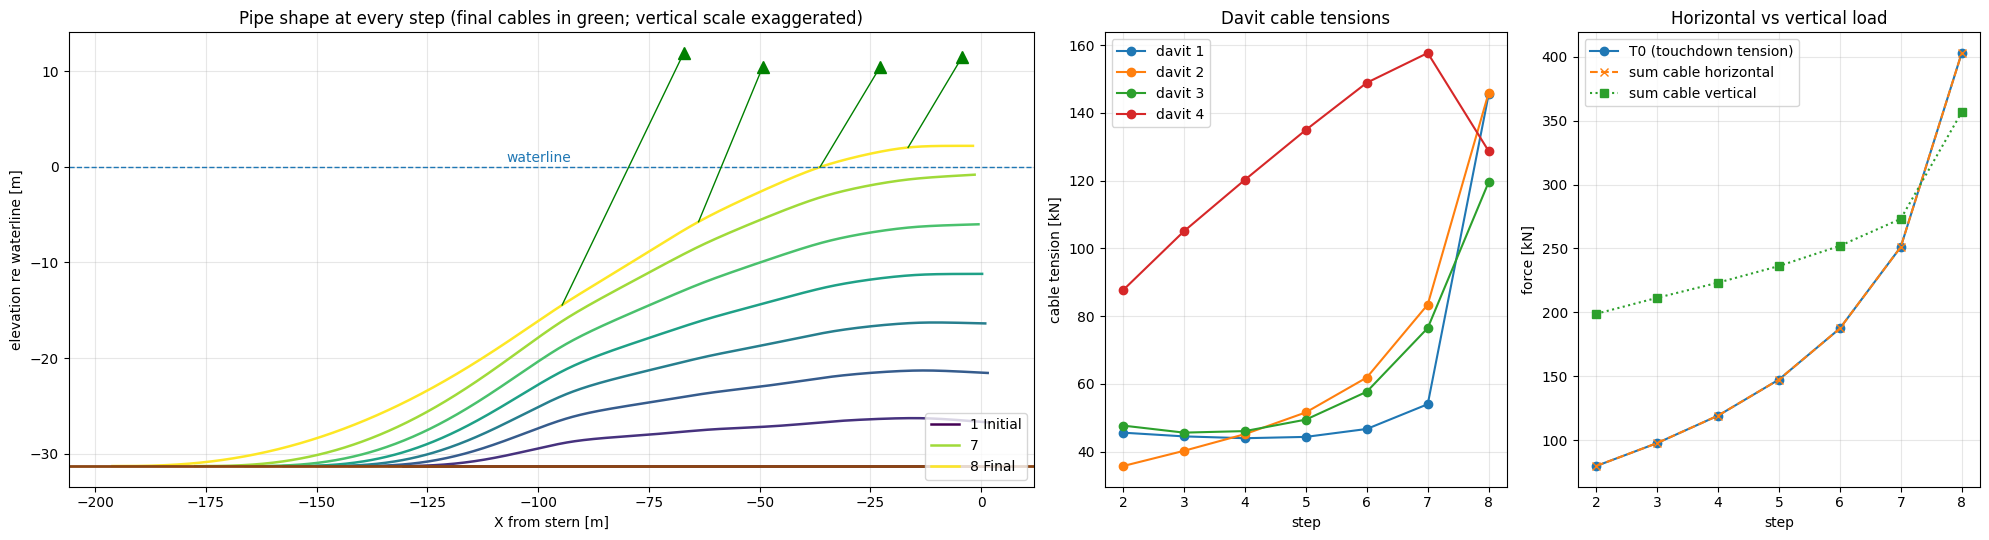

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [2.4, 1, 1]})
cm = plt.cm.viridis(np.linspace(0, 1, len(res)))
for k, r in enumerate(res):
    xs, ys = r["curve"]
    ax[0].plot(xs, ys, color=cm[k], lw=1.8, label=lab[k] if k in (0, len(res)-2, len(res)-1) else None)
ax[0].axhline(0, color="tab:blue", lw=1, ls="--"); ax[0].text(sheave_X.min()-40, 0.5, "waterline", color="tab:blue")
ax[0].axhline(-water_depth, color="saddlebrown", lw=2)
for j in range(n):                                          # cables at the final step
    ax[0].plot([tf["Xj"][j], sheave_X[j]], [tf["Yj"][j] + datum_offset, sheave_Y[j] + datum_offset], "g-", lw=1)
    ax[0].plot(sheave_X[j], sheave_Y[j] + datum_offset, "g^", ms=8)
ax[0].set_xlabel("X from stern [m]"); ax[0].set_ylabel("elevation re waterline [m]")
ax[0].set_title("Pipe shape at every step (final cables in green; vertical scale exaggerated)"); ax[0].grid(alpha=.3); ax[0].legend(loc="lower right")
ax[1].plot(range(2, len(res)+1), Tcab[1:], "o-")
ax[1].set_xlabel("step"); ax[1].set_ylabel("cable tension [kN]"); ax[1].legend([f"davit {j+1}" for j in range(n)]); ax[1].grid(alpha=.3)
ax[1].set_title("Davit cable tensions")
ax[2].plot(range(2, len(res)+1), [r["T0"]/1e3 for r in res[1:]], "o-", label="T0 (touchdown tension)")
ax[2].plot(range(2, len(res)+1), [r["H"].sum()/1e3 for r in res[1:]], "x--", label="sum cable horizontal")
ax[2].plot(range(2, len(res)+1), [r["F"].sum()/1e3 for r in res[1:]], "s:", label="sum cable vertical")
if T0_cap_kN is not None: ax[2].axhline(T0_cap_kN, color="r", ls="--", label="restraint capacity")
ax[2].set_xlabel("step"); ax[2].set_ylabel("force [kN]"); ax[2].grid(alpha=.3); ax[2].legend(); ax[2].set_title("Horizontal vs vertical load")
plt.tight_layout(); plt.show()

## 12. Export (Excel summary in the same grouped layout)

In [12]:
out = "davit_lift_summary_model.xlsx"
table.round(3).to_excel(out, sheet_name="Davit summary")
print("saved", out)

saved davit_lift_summary_model.xlsx


## Notes for use

* **Hook heights / HOB** are what each davit must reach at each step; **TUL** is the winch take-up measured from the geometry-consistent initial cable length (step 1 of this table). Tensions are the *expected* values to monitor.
* **T0** is the horizontal tension the grounded pipe must resist at the touchdown point (seabed friction + the rest of the line). If it is larger than what the seabed can give, the pipe slides toward the barge and the results for that step no longer hold: set `T0_cap_kN` to see this flagged, and consider moving the barge / changing the sheave positions so that the cables are closer to vertical.
* The weight switch at the waterline assumes a **flooded** pipe by default (`weight_case`). For an air-filled pipe use `"air_filled_sub"` or set `w_override` / `w_air_override`.
* Change `share`, `clamp_spacing`, `step_dz`, or paste your own `hob_plan`. If a step shows a slack cable or high stress, shorten the step or change the plan.
* The model is quasi-static. For the offshore procedure confirm the loads with your FE model.